In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

In [7]:
## Read the data in chunks to avoid high memory usage
totals = None

for chunk in pd.read_csv(
    "../data/raw/sales_train_evaluation.csv",
    chunksize=500
):
    # Food products in one California Walmart store
    selected = chunk[
        (chunk["store_id"] == "CA_1") &
        (chunk["cat_id"] == "FOODS")
    ]

    if selected.empty:
        continue

    # Daily sales columns are named d_1, d_2, ...; sum down the rows
    # to get one total per day for this chunk
    sales = selected.filter(regex="^d_").sum()

    if totals is None:
        totals = sales
    else:
        totals = totals.add(sales, fill_value=0)

In [8]:
# Convert the daily totals to a table
daily = totals.rename("units_sold").rename_axis("d").reset_index()
daily["day_number"] = daily["d"].str.extract(r"d_(\d+)").astype(int)

# Attach real dates
calendar = pd.read_csv(
    "../data/raw/calendar.csv",
    usecols=["d", "date"]
)


In [9]:
daily = daily.merge(calendar, on="d", how="left")
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.sort_values("day_number").reset_index(drop=True)

print(daily.head())
print("Number of days:", len(daily))

     d  units_sold  day_number       date
0  d_1        3239           1 2011-01-29
1  d_2        3137           2 2011-01-30
2  d_3        2008           3 2011-01-31
3  d_4        2258           4 2011-02-01
4  d_5        2032           5 2011-02-02
Number of days: 1941


In [10]:
# Seasonal naive: use sales from 7 days earlier
daily["prediction"] = daily["units_sold"].shift(7)

# Evaluate only on our reserved final-test period
test = daily[daily["day_number"].between(1886, 1941)].copy()

mae = mean_absolute_error(
    test["units_sold"],
    test["prediction"]
)

print(f"Seasonal Naive MAE: {mae:.2f} units")

Seasonal Naive MAE: 248.75 units


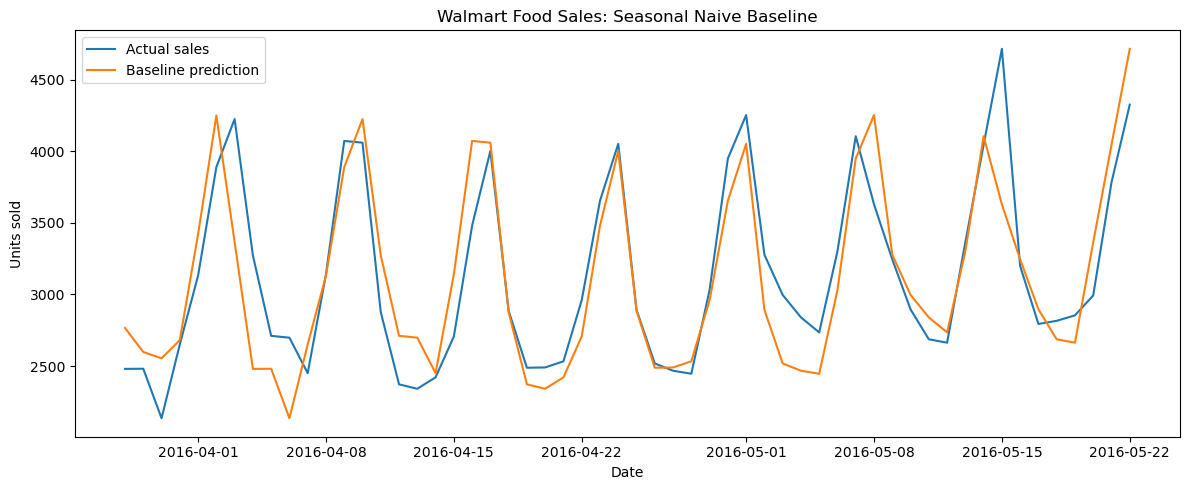

In [11]:
# Plot actual sales against predictions
plt.figure(figsize=(12, 5))
plt.plot(test["date"], test["units_sold"], label="Actual sales")
plt.plot(test["date"], test["prediction"], label="Baseline prediction")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.title("Walmart Food Sales: Seasonal Naive Baseline")
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
# Extract the day of the week
daily["weekday"] = daily["date"].dt.day_name()

# Calculate average units sold for each weekday
weekday_sales = (
    daily.groupby("weekday")["units_sold"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

print(weekday_sales.round(2))

weekday
Monday       2699.48
Tuesday      2379.66
Wednesday    2319.26
Thursday     2348.67
Friday       2824.15
Saturday     3532.36
Sunday       3623.87
Name: units_sold, dtype: float64


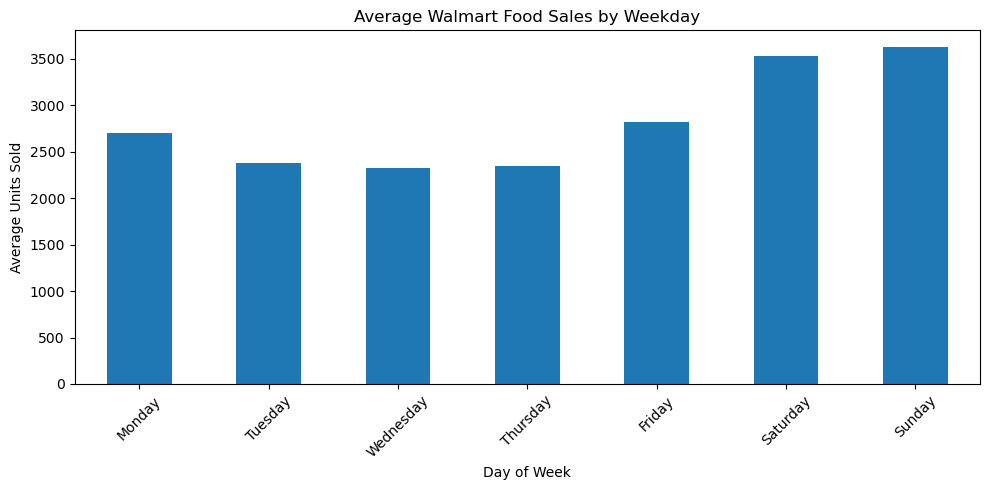

In [13]:
# Visualize the result
plt.figure(figsize=(10, 5))
weekday_sales.plot(kind="bar")

plt.title("Average Walmart Food Sales by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
# Calculate prediction errors
test["absolute_error"] = abs(
    test["units_sold"] - test["prediction"]
)

# Weighted Absolute Percentage Error
wape = (
    test["absolute_error"].sum()
    / test["units_sold"].abs().sum()
) * 100

print(f"MAE: {mae:.2f} units")
print(f"WAPE: {wape:.2f}%")
print(f"Average daily sales: {test['units_sold'].mean():.2f}")

MAE: 248.75 units
WAPE: 7.94%
Average daily sales: 3133.95


In [15]:

# Run this in 01_Exploration.ipynb
daily.to_csv("../data/daily_food_sales.csv", index=False)
